In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from google.colab import files

uploaded = files.upload()

Saving 2019-Oct-sample.csv to 2019-Oct-sample.csv


In [4]:
df = pd.read_csv("2019-Oct-sample.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (500000, 9)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     500000 non-null  object 
 1   event_type     500000 non-null  object 
 2   product_id     500000 non-null  int64  
 3   category_id    500000 non-null  int64  
 4   category_code  341561 non-null  object 
 5   brand          428149 non-null  object 
 6   price          500000 non-null  float64
 7   user_id        500000 non-null  int64  
 8   user_session   500000 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 34.3+ MB


In [6]:
df['event_time'] = pd.to_datetime(df['event_time'])

df = df.sort_values(['user_id', 'event_time'])

df[['user_id', 'event_time', 'event_type', 'user_session']].head(10)

,user_id,event_time,event_type,user_session
387798,244951053,2019-10-01 08:47:35+00:00,view,91769fdf-461b-4e43-9c73-88a07481b75c
388850,244951053,2019-10-01 08:48:28+00:00,view,91769fdf-461b-4e43-9c73-88a07481b75c
1150,306441847,2019-10-01 01:32:09+00:00,view,47641f8a-3aba-471a-8d07-014deccec567
21849,306441847,2019-10-01 02:56:47+00:00,view,47641f8a-3aba-471a-8d07-014deccec567
327950,306441847,2019-10-01 07:58:28+00:00,view,47641f8a-3aba-471a-8d07-014deccec567
361289,306441847,2019-10-01 08:26:14+00:00,view,47641f8a-3aba-471a-8d07-014deccec567
187167,321655812,2019-10-01 05:55:19+00:00,view,880eca1d-d737-4798-a641-d3c87a672df9
188907,321655812,2019-10-01 05:56:57+00:00,view,880eca1d-d737-4798-a641-d3c87a672df9
459944,330585300,2019-10-01 09:46:41+00:00,view,8dfc5232-f93f-4cec-a73e-4913f35bdaaa
469062,330585300,2019-10-01 09:54:51+00:00,view,8dfc5232-f93f-4cec-a73e-4913f35bdaaa


In [7]:
journeys = (
    df.groupby(['user_id', 'user_session'])['event_type']
      .apply(list)
      .reset_index(name='journey')
)

journeys.head(10)

,user_id,user_session,journey
0,244951053,91769fdf-461b-4e43-9c73-88a07481b75c,"[view, view]"
1,306441847,47641f8a-3aba-471a-8d07-014deccec567,"[view, view, view, view]"
2,321655812,880eca1d-d737-4798-a641-d3c87a672df9,"[view, view]"
3,330585300,8dfc5232-f93f-4cec-a73e-4913f35bdaaa,"[view, view, view, view, view, view]"
4,332550649,d24b717d-1956-4a31-b4f4-f82f42705e62,"[view, view, view, view, view, view, view]"
5,348609428,bc4879bf-26fb-43bb-8c2b-260d93185a98,[view]
6,351866718,f791b47c-33f6-470b-8251-08fcddd5a266,[view]
7,360719779,abb1c503-d304-40a5-933d-241d29d8b67e,"[view, view, view]"
8,362699320,6c48ec39-b4be-4e62-a646-6c5d92de098c,"[view, view, view, view, view, view, view]"
9,362972137,a7d81604-ed16-4bf2-afc3-386d12f26547,"[view, view, view]"


In [8]:
journey_counts = (
    journeys['journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

journey_counts.head(10)

,count
journey,
view,42099
view → view,19342
view → view → view,11439
view → view → view → view,7659
view → view → view → view → view,5305
view → view → view → view → view → view,3880
view → view → view → view → view → view → view,2988
view → view → view → view → view → view → view → view,2373
view → view → view → view → view → view → view → view → view,1835


In [9]:
journey_counts = (
    journeys['journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

journey_counts.head(10)

,count
journey,
view,42099
view → view,19342
view → view → view,11439
view → view → view → view,7659
view → view → view → view → view,5305
view → view → view → view → view → view,3880
view → view → view → view → view → view → view,2988
view → view → view → view → view → view → view → view,2373
view → view → view → view → view → view → view → view → view,1835


In [10]:
def simplify_journey(events):
    result = []
    for event in events:
        if not result or event != result[-1]:
            result.append(event)
    return result

journeys['simplified_journey'] = journeys['journey'].apply(simplify_journey)

journeys[['user_id', 'user_session', 'simplified_journey']].head(10)

,user_id,user_session,simplified_journey
0,244951053,91769fdf-461b-4e43-9c73-88a07481b75c,[view]
1,306441847,47641f8a-3aba-471a-8d07-014deccec567,[view]
2,321655812,880eca1d-d737-4798-a641-d3c87a672df9,[view]
3,330585300,8dfc5232-f93f-4cec-a73e-4913f35bdaaa,[view]
4,332550649,d24b717d-1956-4a31-b4f4-f82f42705e62,[view]
5,348609428,bc4879bf-26fb-43bb-8c2b-260d93185a98,[view]
6,351866718,f791b47c-33f6-470b-8251-08fcddd5a266,[view]
7,360719779,abb1c503-d304-40a5-933d-241d29d8b67e,[view]
8,362699320,6c48ec39-b4be-4e62-a646-6c5d92de098c,[view]
9,362972137,a7d81604-ed16-4bf2-afc3-386d12f26547,[view]


In [11]:
simplified_counts = (
    journeys['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

simplified_counts.head(10)

,count
simplified_journey,
view,107008
view → purchase → view,2558
view → purchase,2210
view → cart → view,1156
view → cart → purchase → view,1087
view → cart → purchase,906
view → cart,843
view → purchase → view → purchase → view,247
view → purchase → view → purchase,156


In [12]:
multi_stage = journeys[
    journeys['simplified_journey'].apply(len) >= 2
].copy()

multi_stage.shape

(10409, 4)

In [13]:
multi_stage_counts = (
    multi_stage['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

multi_stage_counts.head(15)

,count
simplified_journey,
view → purchase → view,2558
view → purchase,2210
view → cart → view,1156
view → cart → purchase → view,1087
view → cart → purchase,906
view → cart,843
view → purchase → view → purchase → view,247
view → purchase → view → purchase,156
view → cart → view → cart → purchase → view,98


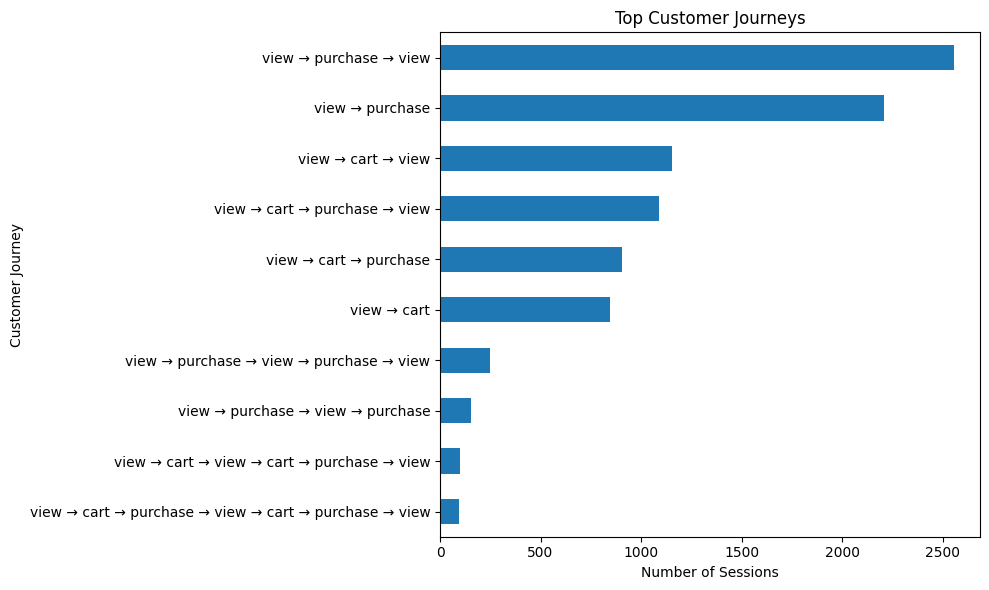

In [14]:
import matplotlib.pyplot as plt

top_journeys = multi_stage_counts.head(10)

top_journeys.sort_values().plot(kind='barh', figsize=(10, 6))

plt.xlabel('Number of Sessions')
plt.ylabel('Customer Journey')
plt.title('Top Customer Journeys')
plt.tight_layout()
plt.show()

In [15]:
multi_stage['has_purchase'] = multi_stage['simplified_journey'].apply(
    lambda x: 'purchase' in x
)

In [16]:
purchase_summary = multi_stage['has_purchase'].value_counts()
purchase_summary

,count
has_purchase,
True,8218
False,2191


In [17]:
purchase_percentage = (
    multi_stage['has_purchase']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

purchase_percentage

,proportion
has_purchase,
True,78.95
False,21.05


In [18]:
purchase_ending = multi_stage[
    multi_stage['simplified_journey'].apply(lambda x: x[-1] == 'purchase')
]

purchase_ending_counts = (
    purchase_ending['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

purchase_ending_counts.head(10)

,count
simplified_journey,
view → purchase,2210
view → cart → purchase,906
view → purchase → view → purchase,156
view → cart → view → cart → purchase,88
view → cart → view → purchase,58
view → cart → purchase → view → cart → purchase,51
view → cart → purchase → view → purchase,25
view → purchase → view → cart → purchase,22
view → purchase → view → purchase → view → purchase,19


In [19]:
non_purchase_ending = multi_stage[
    multi_stage['simplified_journey'].apply(lambda x: x[-1] != 'purchase')
]

non_purchase_ending_counts = (
    non_purchase_ending['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

non_purchase_ending_counts.head(10)

,count
simplified_journey,
view → purchase → view,2558
view → cart → view,1156
view → cart → purchase → view,1087
view → cart,843
view → purchase → view → purchase → view,247
view → cart → view → cart → purchase → view,98
view → cart → purchase → view → cart → purchase → view,94
view → cart → view → cart → view,79
view → cart → view → cart,65


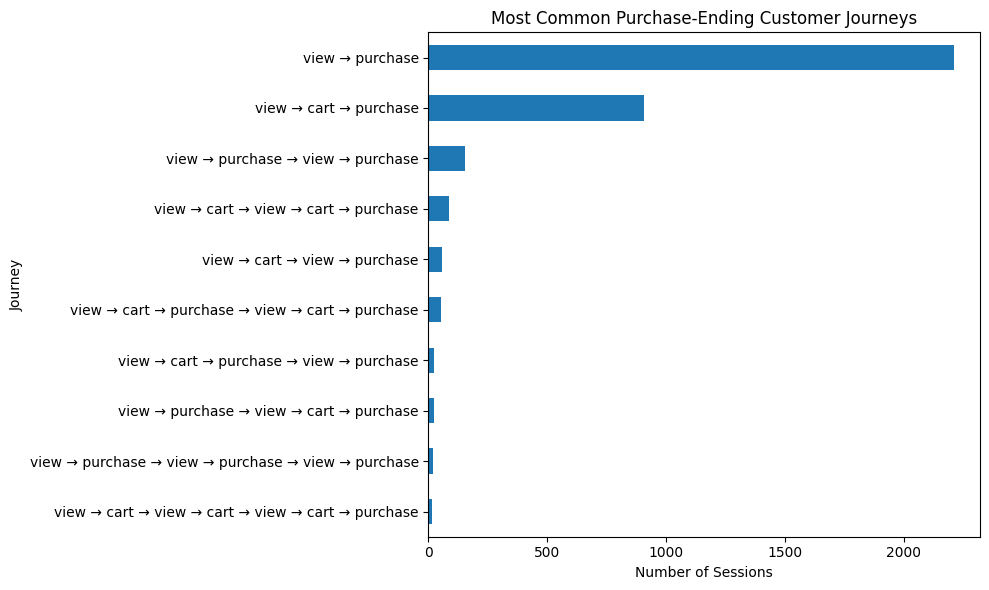

In [20]:
purchase_ending_counts.head(10).sort_values().plot(
    kind='barh', figsize=(10, 6)
)

plt.xlabel('Number of Sessions')
plt.ylabel('Journey')
plt.title('Most Common Purchase-Ending Customer Journeys')
plt.tight_layout()
plt.show()

In [21]:
from collections import Counter

transitions = Counter()

for journey in journeys['simplified_journey']:
    for i in range(len(journey) - 1):
        transitions[(journey[i], journey[i+1])] += 1

In [22]:
transition_df = pd.DataFrame(
    transitions.items(),
    columns=['transition', 'count']
)

transition_df[['from_event', 'to_event']] = pd.DataFrame(
    transition_df['transition'].tolist(),
    index=transition_df.index
)

transition_df = transition_df.drop(columns='transition')
transition_df = transition_df.sort_values('count', ascending=False)

transition_df.head(10)

,count,from_event,to_event
2,6462,view,purchase
0,6104,view,cart
4,6019,purchase,view
3,3167,cart,purchase
1,2030,cart,view
5,29,purchase,cart


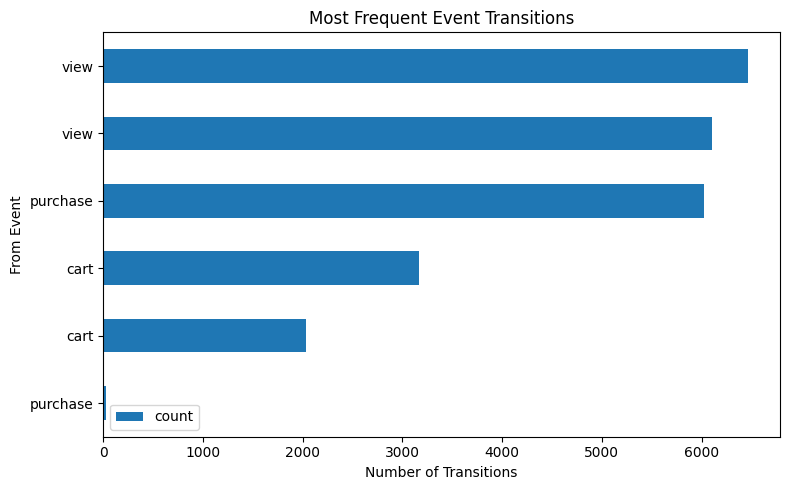

In [23]:
transition_df.head(10).sort_values('count').plot(
    x='from_event',
    y='count',
    kind='barh',
    figsize=(8, 5)
)

plt.xlabel('Number of Transitions')
plt.ylabel('From Event')
plt.title('Most Frequent Event Transitions')
plt.tight_layout()
plt.show()

In [24]:
transition_df['transition_label'] = (
    transition_df['from_event'] + ' → ' + transition_df['to_event']
)

transition_df.head(10)

,count,from_event,to_event,transition_label
2,6462,view,purchase,view → purchase
0,6104,view,cart,view → cart
4,6019,purchase,view,purchase → view
3,3167,cart,purchase,cart → purchase
1,2030,cart,view,cart → view
5,29,purchase,cart,purchase → cart


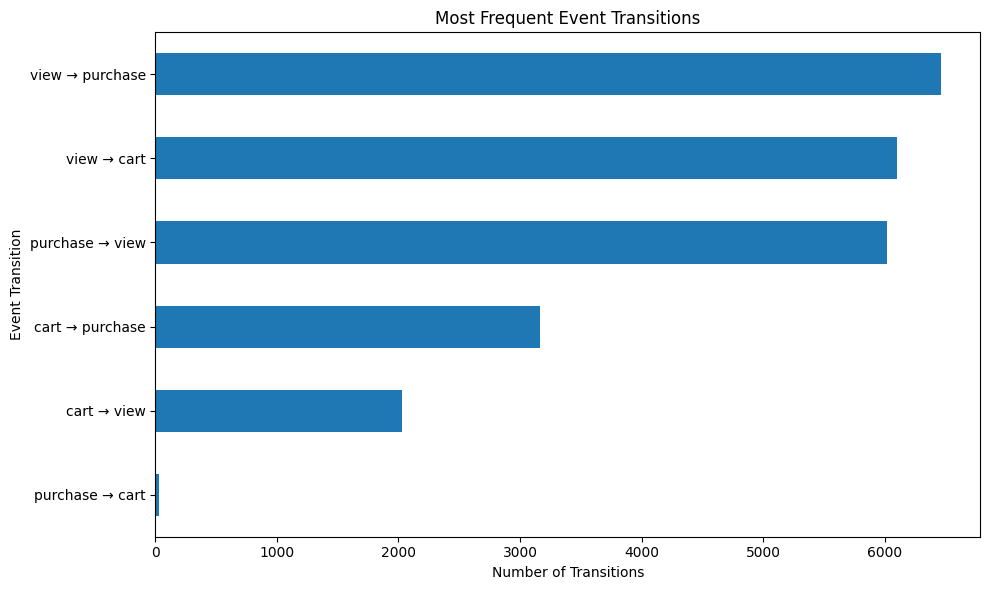

In [25]:
top_transitions = transition_df.head(10).sort_values('count')

top_transitions.plot(
    x='transition_label',
    y='count',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.xlabel('Number of Transitions')
plt.ylabel('Event Transition')
plt.title('Most Frequent Event Transitions')
plt.tight_layout()
plt.show()

In [26]:
journey_results = multi_stage_counts.head(20)
transition_results = transition_df.head(20)

print("Top Journey Patterns:")
display(journey_results)

print("\nTop Event Transitions:")
display(transition_results)

Top Journey Patterns:


,count
simplified_journey,
view → purchase → view,2558
view → purchase,2210
view → cart → view,1156
view → cart → purchase → view,1087
view → cart → purchase,906
view → cart,843
view → purchase → view → purchase → view,247
view → purchase → view → purchase,156
view → cart → view → cart → purchase → view,98



Top Event Transitions:


,count,from_event,to_event,transition_label
2,6462,view,purchase,view → purchase
0,6104,view,cart,view → cart
4,6019,purchase,view,purchase → view
3,3167,cart,purchase,cart → purchase
1,2030,cart,view,cart → view
5,29,purchase,cart,purchase → cart


In [27]:
comparison = pd.DataFrame({
    'Approach': [
        'Sequence / Journey Analysis',
        'Transition Analysis'
    ],
    'What_it_shows': [
        'Complete user paths across multiple events',
        'Direct movement between consecutive events'
    ],
    'Example': [
        'view → cart → purchase',
        'cart → purchase'
    ]
})

comparison

,Approach,What_it_shows,Example
0,Sequence / Journey Analysis,Complete user paths across multiple events,view → cart → purchase
1,Transition Analysis,Direct movement between consecutive events,cart → purchase


In [28]:
import time

start = time.time()

_ = (
    journeys['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

sequence_time = time.time() - start

start = time.time()

_ = transition_df.sort_values('count', ascending=False)

transition_time = time.time() - start

print("Sequence analysis time:", round(sequence_time, 4), "seconds")
print("Transition analysis time:", round(transition_time, 4), "seconds")

Sequence analysis time: 0.0367 seconds
Transition analysis time: 0.0009 seconds


In [29]:
performance = pd.DataFrame({
    'Approach': ['Sequence / Journey', 'Transition'],
    'Execution_Time_Seconds': [sequence_time, transition_time]
})

performance

,Approach,Execution_Time_Seconds
0,Sequence / Journey,0.036657
1,Transition,0.000923


In [30]:
start = time.time()

sequence_result = (
    journeys['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

sequence_full_time = time.time() - start

print("Full Sequence/Journey time:",
      round(sequence_full_time, 4), "seconds")

Full Sequence/Journey time: 0.041 seconds


In [31]:
start = time.time()

transition_counter = Counter()

for journey in journeys['simplified_journey']:
    for i in range(len(journey) - 1):
        transition_counter[(journey[i], journey[i+1])] += 1

transition_full_time = time.time() - start

print("Full Transition analysis time:",
      round(transition_full_time, 4), "seconds")

Full Transition analysis time: 0.1055 seconds


In [32]:
performance = pd.DataFrame({
    'Approach': ['Sequence / Journey', 'Transition'],
    'Execution_Time_Seconds': [
        sequence_full_time,
        transition_full_time
    ]
})

performance

,Approach,Execution_Time_Seconds
0,Sequence / Journey,0.040973
1,Transition,0.105519


In [33]:
print("Unique journey patterns:", sequence_result.shape[0])
print("Unique event transitions:", transition_df.shape[0])

Unique journey patterns: 171
Unique event transitions: 6


In [34]:
o2_comparison = pd.DataFrame({
    'Approach': ['Sequence / Journey Analysis', 'Transition Analysis'],
    'Analysis_Level': [
        'Complete multi-event paths',
        'Consecutive event pairs'
    ],
    'Execution_Time_Seconds': [
        sequence_full_time,
        transition_full_time
    ]
})

o2_comparison

,Approach,Analysis_Level,Execution_Time_Seconds
0,Sequence / Journey Analysis,Complete multi-event paths,0.040973
1,Transition Analysis,Consecutive event pairs,0.105519


In [35]:
o2_comparison.to_csv(
    'O2_approach_comparison.csv',
    index=False
)

journey_results.to_csv(
    'O2_journey_results.csv',
    header=['count']
)

transition_results.to_csv(
    'O2_transition_results.csv',
    index=False
)

print("O2 result files saved.")

O2 result files saved.


In [36]:
invalid_journeys = journeys[
    journeys['simplified_journey'].apply(len) == 0
]

print("Invalid journeys:", len(invalid_journeys))

Invalid journeys: 0


In [37]:
valid_events = {'view', 'cart', 'purchase', 'remove_from_cart'}

invalid_events = set(
    event
    for journey in journeys['simplified_journey']
    for event in journey
    if event not in valid_events
)

print("Unexpected event types:", invalid_events)

Unexpected event types: set()


In [38]:
purchase_journey_count = journeys[
    journeys['simplified_journey'].apply(lambda x: 'purchase' in x)
].shape[0]

print("Journeys containing purchase:", purchase_journey_count)

Journeys containing purchase: 8256


In [39]:
print("Invalid journeys:", len(invalid_journeys))

Invalid journeys: 0


In [40]:
print("Unexpected event types:", invalid_events)

Unexpected event types: set()


In [41]:
ac1_summary = pd.DataFrame({
    'Check': [
        'Invalid journeys',
        'Unexpected event types',
        'Journeys containing purchase'
    ],
    'Result': [
        len(invalid_journeys),
        str(invalid_events),
        purchase_journey_count
    ]
})

ac1_summary

,Check,Result
0,Invalid journeys,0
1,Unexpected event types,set()
2,Journeys containing purchase,8256


In [42]:
session_times = df.groupby(
    ['user_id', 'user_session']
)['event_time'].agg(['min', 'max'])

session_times['duration_minutes'] = (
    session_times['max'] - session_times['min']
).dt.total_seconds() / 60

session_times['duration_minutes'].describe()

,duration_minutes
count,117459.000000
mean,4.716244
std,15.791971
min,0.000000
25%,0.000000
50%,0.950000
75%,3.966667
max,539.383333


In [43]:
session_times[
    session_times['duration_minutes'] > 60
].head(10)

,,min,max,duration_minutes
user_id,user_session,,,
306441847,47641f8a-3aba-471a-8d07-014deccec567,2019-10-01 01:32:09+00:00,2019-10-01 08:26:14+00:00,414.083333
437548958,6ab3e21a-5d98-48d8-97a3-6fc1aa39746c,2019-10-01 07:25:39+00:00,2019-10-01 10:01:19+00:00,155.666667
463020196,2725a92d-aed5-4643-9e0e-d525a3aff091,2019-10-01 06:26:43+00:00,2019-10-01 07:55:56+00:00,89.216667
463570586,b69b5796-5512-4691-9bea-4017f40b9234,2019-10-01 02:58:43+00:00,2019-10-01 04:45:35+00:00,106.866667
476935833,40579b7b-99aa-4321-9608-a5bd2aae9221,2019-10-01 03:01:18+00:00,2019-10-01 10:10:29+00:00,429.183333
477006909,094c8cdb-e96c-45c4-b2bc-a05c36346daf,2019-10-01 06:58:10+00:00,2019-10-01 08:45:12+00:00,107.033333
477121012,413b498a-71d5-49fa-b896-1761ab981917,2019-10-01 01:06:56+00:00,2019-10-01 10:04:09+00:00,537.216667
480112030,b796f373-12c8-42a9-bfa6-958566729f70,2019-10-01 02:59:58+00:00,2019-10-01 04:26:30+00:00,86.533333
486126757,855a0e15-0d5e-46cf-8f5d-fdcc04dc767e,2019-10-01 04:17:10+00:00,2019-10-01 08:07:59+00:00,230.816667


In [44]:
long_sessions = (
    session_times['duration_minutes'] > 60
).sum()

print("Sessions longer than 60 minutes:", long_sessions)

Sessions longer than 60 minutes: 1227


In [45]:
session_times.sort_values(
    'duration_minutes',
    ascending=False
).head(10)

,,min,max,duration_minutes
user_id,user_session,,,
549305293,b56fda28-fdd0-4891-926f-9d236631b301,2019-10-01 00:28:44+00:00,2019-10-01 09:28:07+00:00,539.383333
477121012,413b498a-71d5-49fa-b896-1761ab981917,2019-10-01 01:06:56+00:00,2019-10-01 10:04:09+00:00,537.216667
554746974,028a2161-3ed0-4040-9d57-ad4bca6786a5,2019-10-01 01:20:42+00:00,2019-10-01 10:14:42+00:00,534.000000
537311224,44f61fa9-9fa0-42f0-b006-64e644450efa,2019-10-01 01:04:03+00:00,2019-10-01 09:51:56+00:00,527.883333
551508458,eb9a8d4b-da50-43c5-b2c2-21fe9487a175,2019-10-01 00:30:16+00:00,2019-10-01 08:58:25+00:00,508.150000
549984018,1d638801-09dc-4e1b-ade4-b51edf61fe00,2019-10-01 01:19:10+00:00,2019-10-01 09:30:52+00:00,491.700000
547353797,7218a861-2bc1-4bee-b323-4cff373cd51b,2019-10-01 01:56:04+00:00,2019-10-01 10:07:21+00:00,491.283333
513857808,a5c969fe-48a8-414a-9b97-8dab71296a0f,2019-10-01 01:57:20+00:00,2019-10-01 09:48:59+00:00,471.650000
555257966,79b8085d-cc4b-40ff-870f-14d3327c61f3,2019-10-01 02:32:31+00:00,2019-10-01 10:20:51+00:00,468.333333


In [46]:
session_event_counts = df.groupby(
    ['user_id', 'user_session']
).size().reset_index(name='event_count')

session_check = session_times.reset_index().merge(
    session_event_counts,
    on=['user_id', 'user_session']
)

session_check.sort_values(
    'duration_minutes',
    ascending=False
).head(10)

,user_id,user_session,min,max,duration_minutes,event_count
86584,549305293,b56fda28-fdd0-4891-926f-9d236631b301,2019-10-01 00:28:44+00:00,2019-10-01 09:28:07+00:00,539.383333,2
236,477121012,413b498a-71d5-49fa-b896-1761ab981917,2019-10-01 01:06:56+00:00,2019-10-01 10:04:09+00:00,537.216667,2
98925,554746974,028a2161-3ed0-4040-9d57-ad4bca6786a5,2019-10-01 01:20:42+00:00,2019-10-01 10:14:42+00:00,534.000000,2
67093,537311224,44f61fa9-9fa0-42f0-b006-64e644450efa,2019-10-01 01:04:03+00:00,2019-10-01 09:51:56+00:00,527.883333,2
90750,551508458,eb9a8d4b-da50-43c5-b2c2-21fe9487a175,2019-10-01 00:30:16+00:00,2019-10-01 08:58:25+00:00,508.150000,2
87802,549984018,1d638801-09dc-4e1b-ade4-b51edf61fe00,2019-10-01 01:19:10+00:00,2019-10-01 09:30:52+00:00,491.700000,3
82754,547353797,7218a861-2bc1-4bee-b323-4cff373cd51b,2019-10-01 01:56:04+00:00,2019-10-01 10:07:21+00:00,491.283333,4
15965,513857808,a5c969fe-48a8-414a-9b97-8dab71296a0f,2019-10-01 01:57:20+00:00,2019-10-01 09:48:59+00:00,471.650000,3
101258,555257966,79b8085d-cc4b-40ff-870f-14d3327c61f3,2019-10-01 02:32:31+00:00,2019-10-01 10:20:51+00:00,468.333333,35
95589,553638632,ae63befb-8b54-4aae-a5f1-78d20255c55e,2019-10-01 00:05:59+00:00,2019-10-01 07:37:41+00:00,451.700000,2


In [47]:
single_event_sessions = (
    session_event_counts['event_count'] == 1
).sum()

print(
    "Single-event sessions:",
    single_event_sessions
)

Single-event sessions: 42139


In [48]:
multi_event_purchase = multi_stage[
    multi_stage['simplified_journey'].apply(
        lambda x: 'purchase' in x and len(x) > 2
    )
].copy()

print(
    "Multi-event journeys containing purchase:",
    len(multi_event_purchase)
)

Multi-event journeys containing purchase: 5954


In [49]:
multi_event_purchase[
    ['user_id', 'user_session', 'simplified_journey']
].head(10)

,user_id,user_session,simplified_journey
194,469200473,f0247630-e2eb-4a99-9fea-cd9d027be041,"[view, cart, purchase, view]"
530,502469352,45d36b19-5a27-42c6-8f0e-a76a832e8d1e,"[view, purchase, view]"
551,503283510,b013451e-8bf8-4e3f-a96b-ebfbd34f810f,"[view, cart, purchase, view]"
569,504429960,54243b1c-14aa-4c29-9ddd-6607865700a1,"[view, purchase, view]"
738,512365496,d5aa25d2-afb4-4644-8edc-d8004c03091d,"[view, purchase, view]"
739,512365722,3155c5c9-7453-404e-ace4-73957a0bc720,"[view, purchase, view]"
758,512366873,599c84e2-c884-4f30-8d36-ae0ea38a8a45,"[view, purchase, view]"
814,512370660,ad0da253-337b-49a9-9353-8481565b0fa5,"[view, purchase, view]"
842,512372458,862ad742-ccb6-4429-99a3-a52990e346e9,"[view, purchase, view, purchase, view, purchas..."
845,512372746,b8dfbaef-53a8-471d-a766-e57891d38e3a,"[view, purchase, view]"


In [50]:
non_first_purchase = multi_event_purchase[
    multi_event_purchase['simplified_journey'].apply(
        lambda x: x[0] != 'purchase'
    )
]

print(
    "Journeys where purchase occurs after another event:",
    len(non_first_purchase)
)

Journeys where purchase occurs after another event: 5940


In [51]:
pre_purchase_paths = (
    non_first_purchase['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

pre_purchase_paths.head(10)

,count
simplified_journey,
view → purchase → view,2558
view → cart → purchase → view,1087
view → cart → purchase,906
view → purchase → view → purchase → view,247
view → purchase → view → purchase,156
view → cart → view → cart → purchase → view,98
view → cart → purchase → view → cart → purchase → view,94
view → cart → view → cart → purchase,88
view → cart → view → purchase,58


In [52]:
multiple_before_purchase = non_first_purchase[
    non_first_purchase['simplified_journey'].apply(
        lambda x: x.index('purchase') >= 2
    )
]

print(
    "Journeys with 2+ events before purchase:",
    len(multiple_before_purchase)
)

Journeys with 2+ events before purchase: 2764


In [53]:
ac2_summary = pd.DataFrame({
    'Check': [
        'Sessions longer than 60 minutes',
        'Single-event sessions',
        'Journeys with purchase after another event',
        'Journeys with 2+ events before purchase'
    ],
    'Result': [
        long_sessions,
        single_event_sessions,
        len(non_first_purchase),
        len(multiple_before_purchase)
    ]
})

ac2_summary

,Check,Result
0,Sessions longer than 60 minutes,1227
1,Single-event sessions,42139
2,Journeys with purchase after another event,5940
3,Journeys with 2+ events before purchase,2764


In [54]:
split_date = df['event_time'].quantile(0.8)

development_df = df[df['event_time'] <= split_date].copy()
validation_df = df[df['event_time'] > split_date].copy()

print("Development rows:", len(development_df))
print("Validation rows:", len(validation_df))
print("Split date:", split_date)

Development rows: 400019
Validation rows: 99981
Split date: 2019-10-01 08:57:16+00:00


In [55]:
validation_journeys = (
    validation_df
    .sort_values(['user_id', 'event_time'])
    .groupby(['user_id', 'user_session'])['event_type']
    .apply(list)
    .reset_index(name='journey')
)

validation_journeys['simplified_journey'] = (
    validation_journeys['journey'].apply(simplify_journey)
)

validation_journeys.head()

,user_id,user_session,journey,simplified_journey
0,330585300,8dfc5232-f93f-4cec-a73e-4913f35bdaaa,"[view, view, view, view, view, view]",[view]
1,360719779,abb1c503-d304-40a5-933d-241d29d8b67e,"[view, view, view]",[view]
2,362972137,a7d81604-ed16-4bf2-afc3-386d12f26547,"[view, view, view]",[view]
3,376375533,e0b2446d-e6fa-4993-a0f6-2efbde5f3d93,"[view, view, view]",[view]
4,386197999,048a8a86-7b95-4f8b-862f-337253ef2a5f,"[view, view, view, view]",[view]


In [56]:
validation_purchase_count = validation_journeys[
    validation_journeys['simplified_journey'].apply(
        lambda x: 'purchase' in x
    )
].shape[0]

print(
    "Validation journeys containing purchase:",
    validation_purchase_count
)

Validation journeys containing purchase: 1738


In [57]:
validation_journeys.shape

(24415, 4)

In [58]:
validation_purchase_count = validation_journeys[
    validation_journeys['simplified_journey'].apply(
        lambda x: 'purchase' in x
    )
].shape[0]

print("Validation journeys containing purchase:", validation_purchase_count)

Validation journeys containing purchase: 1738


In [59]:
validation_purchase_percentage = (
    validation_purchase_count / len(validation_journeys) * 100
)

print(
    "Validation purchase journey percentage:",
    round(validation_purchase_percentage, 2),
    "%"
)

Validation purchase journey percentage: 7.12 %


In [60]:
development_journeys = (
    development_df
    .sort_values(['user_id', 'event_time'])
    .groupby(['user_id', 'user_session'])['event_type']
    .apply(list)
    .reset_index(name='journey')
)

development_journeys['simplified_journey'] = (
    development_journeys['journey'].apply(simplify_journey)
)

development_purchase_count = development_journeys[
    development_journeys['simplified_journey'].apply(
        lambda x: 'purchase' in x
    )
].shape[0]

development_purchase_percentage = (
    development_purchase_count / len(development_journeys) * 100
)

print("Development journeys:", len(development_journeys))
print("Development purchase journeys:", development_purchase_count)
print("Development purchase percentage:",
      round(development_purchase_percentage, 2), "%")

Development journeys: 94408
Development purchase journeys: 6531
Development purchase percentage: 6.92 %


In [61]:
print("Validation journeys:", len(validation_journeys))
print("Validation purchase journeys:", validation_purchase_count)
print(
    "Validation purchase percentage:",
    round(validation_purchase_percentage, 2),
    "%"
)

Validation journeys: 24415
Validation purchase journeys: 1738
Validation purchase percentage: 7.12 %


In [62]:
ac3_summary = pd.DataFrame({
    'Partition': ['Development', 'Validation'],
    'Journeys': [
        len(development_journeys),
        len(validation_journeys)
    ],
    'Purchase_Journeys': [
        development_purchase_count,
        validation_purchase_count
    ],
    'Purchase_Percentage': [
        round(development_purchase_percentage, 2),
        round(validation_purchase_percentage, 2)
    ]
})

ac3_summary

,Partition,Journeys,Purchase_Journeys,Purchase_Percentage
0,Development,94408,6531,6.92
1,Validation,24415,1738,7.12


In [63]:
print("Development latest event:", development_df['event_time'].max())
print("Validation earliest event:", validation_df['event_time'].min())

print(
    "Time separation valid:",
    development_df['event_time'].max() < validation_df['event_time'].min()
)

Development latest event: 2019-10-01 08:57:16+00:00
Validation earliest event: 2019-10-01 08:57:17+00:00
Time separation valid: True


In [64]:
df = df.reset_index(drop=True)
df['source_row_id'] = df.index

df[['source_row_id', 'event_time', 'event_type', 'user_id', 'user_session']].head()

,source_row_id,event_time,event_type,user_id,user_session
0,0,2019-10-01 08:47:35+00:00,view,244951053,91769fdf-461b-4e43-9c73-88a07481b75c
1,1,2019-10-01 08:48:28+00:00,view,244951053,91769fdf-461b-4e43-9c73-88a07481b75c
2,2,2019-10-01 01:32:09+00:00,view,306441847,47641f8a-3aba-471a-8d07-014deccec567
3,3,2019-10-01 02:56:47+00:00,view,306441847,47641f8a-3aba-471a-8d07-014deccec567
4,4,2019-10-01 07:58:28+00:00,view,306441847,47641f8a-3aba-471a-8d07-014deccec567


In [65]:
validation_df = df[df['event_time'] > split_date].copy()

print("Validation rows:", len(validation_df))
print("Unique source rows:", validation_df['source_row_id'].nunique())

Validation rows: 99981
Unique source rows: 99981


In [66]:
lineage_check = (
    len(validation_df) == validation_df['source_row_id'].nunique()
)

print("All validation rows have unique source IDs:", lineage_check)

All validation rows have unique source IDs: True


In [67]:
validation_journeys = (
    validation_df
    .sort_values(['user_id', 'user_session', 'event_time'])
    .groupby(['user_id', 'user_session'])
    .agg(
        journey=('event_type', list),
        source_rows=('source_row_id', list)
    )
    .reset_index()
)

validation_journeys['simplified_journey'] = (
    validation_journeys['journey'].apply(simplify_journey)
)

validation_journeys.head()

,user_id,user_session,journey,source_rows,simplified_journey
0,330585300,8dfc5232-f93f-4cec-a73e-4913f35bdaaa,"[view, view, view, view, view, view]","[8, 9, 10, 11, 12, 13]",[view]
1,360719779,abb1c503-d304-40a5-933d-241d29d8b67e,"[view, view, view]","[23, 24, 25]",[view]
2,362972137,a7d81604-ed16-4bf2-afc3-386d12f26547,"[view, view, view]","[33, 34, 35]",[view]
3,376375533,e0b2446d-e6fa-4993-a0f6-2efbde5f3d93,"[view, view, view]","[49, 50, 51]",[view]
4,386197999,048a8a86-7b95-4f8b-862f-337253ef2a5f,"[view, view, view, view]","[59, 60, 61, 62]",[view]


In [68]:
validation_journeys['source_count'] = (
    validation_journeys['source_rows'].apply(len)
)

print(
    "Journey source rows:",
    validation_journeys['source_count'].sum()
)

print(
    "Validation source rows:",
    len(validation_df)
)

Journey source rows: 99981
Validation source rows: 99981


In [69]:
print(
    "Complete lineage:",
    validation_journeys['source_count'].sum() == len(validation_df)
)

Complete lineage: True


In [70]:
validation_source_purchase_rows = validation_df[
    validation_df['event_type'] == 'purchase'
]['source_row_id'].nunique()

validation_purchase_journeys = validation_journeys[
    validation_journeys['simplified_journey'].apply(
        lambda x: 'purchase' in x
    )
]

journey_purchase_source_rows = set(
    row_id
    for rows in validation_purchase_journeys['source_rows']
    for row_id in rows
    if row_id in set(
        validation_df[
            validation_df['event_type'] == 'purchase'
        ]['source_row_id']
    )
)

print("Purchase source rows:", validation_source_purchase_rows)
print("Purchase rows linked to purchase journeys:", len(journey_purchase_source_rows))

Purchase source rows: 2094
Purchase rows linked to purchase journeys: 2094


In [71]:
print(
    "Purchase lineage reconciled:",
    validation_source_purchase_rows == len(journey_purchase_source_rows)
)

Purchase lineage reconciled: True


In [72]:
lineage_coverage = (
    validation_journeys['source_count'].sum()
    / len(validation_df)
) * 100

print("End-to-end lineage coverage:", round(lineage_coverage, 2), "%")

End-to-end lineage coverage: 100.0 %


In [73]:
import sys
import pandas as pd
import numpy as np

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.1.3


In [74]:
print("Dataset rows:", len(df))
print("Dataset columns:", len(df.columns))
print("Unique users:", df['user_id'].nunique())
print("Unique sessions:", df['user_session'].nunique())

Dataset rows: 500000
Dataset columns: 10
Unique users: 89124
Unique sessions: 117455


In [75]:
import platform

print("System:", platform.system())
print("Machine:", platform.machine())
print("Processor:", platform.processor())

System: Linux
Machine: x86_64
Processor: x86_64


In [76]:
id="r8m2k4"
memory_usage_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

print("DataFrame memory usage:", round(memory_usage_mb, 2), "MB")

DataFrame memory usage: 141.52 MB


In [77]:
id="h6v3p9"
import psutil

memory = psutil.virtual_memory()

print("Total system memory:", round(memory.total / (1024**3), 2), "GB")
print("Available memory:", round(memory.available / (1024**3), 2), "GB")

Total system memory: 12.67 GB
Available memory: 10.98 GB


In [78]:
id="q4n7x2"
ac4_environment = pd.DataFrame({
    'Parameter': [
        'Python',
        'Pandas',
        'NumPy',
        'Dataset rows',
        'Dataset columns',
        'Unique users',
        'Unique sessions',
        'System',
        'Architecture',
        'DataFrame memory (MB)'
    ],
    'Value': [
        '3.13.15',
        '2.2.3',
        '2.1.3',
        500000,
        10,
        89124,
        117455,
        'Linux',
        'x86_64',
        round(memory_usage_mb, 2)
    ]
})

ac4_environment

,Parameter,Value
0,Python,3.13.15
1,Pandas,2.2.3
2,NumPy,2.1.3
3,Dataset rows,500000
4,Dataset columns,10
5,Unique users,89124
6,Unique sessions,117455
7,System,Linux
8,Architecture,x86_64
9,DataFrame memory (MB),141.52


In [79]:
id="f7k3m2"
benchmark_journeys = journeys[['user_id', 'user_session', 'simplified_journey']].copy()

print("Benchmark journeys:", len(benchmark_journeys))
print("Benchmark users:", benchmark_journeys['user_id'].nunique())
print("Benchmark sessions:", benchmark_journeys['user_session'].nunique())

Benchmark journeys: 117459
Benchmark users: 89124
Benchmark sessions: 117455


In [80]:
id="b2r8q5"
import time

start = time.perf_counter()

sequence_result = (
    benchmark_journeys['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

sequence_time = time.perf_counter() - start

print("Sequence analysis time:",
      round(sequence_time, 6), "seconds")

Sequence analysis time: 0.037554 seconds


In [81]:
id="n6w4p1"
start = time.perf_counter()

transition_counter = Counter()

for journey in benchmark_journeys['simplified_journey']:
    for i in range(len(journey) - 1):
        transition_counter[(journey[i], journey[i+1])] += 1

transition_time = time.perf_counter() - start

print("Transition analysis time:",
      round(transition_time, 6), "seconds")

Transition analysis time: 0.059875 seconds


In [82]:
ac4_benchmark = pd.DataFrame({
    'Approach': [
        'Sequence / Journey Analysis',
        'Transition Analysis'
    ],
    'Dataset_Rows': [500000, 500000],
    'Dataset_Sessions': [117455, 117455],
    'Execution_Time_Seconds': [
        round(sequence_time, 6),
        round(transition_time, 6)
    ],
    'Python': ['3.13.15', '3.13.15'],
    'Pandas': ['2.2.3', '2.2.3'],
    'NumPy': ['2.1.3', '2.1.3'],
    'System': ['Linux', 'Linux'],
    'Architecture': ['x86_64', 'x86_64']
})

ac4_benchmark

,Approach,Dataset_Rows,Dataset_Sessions,Execution_Time_Seconds,Python,Pandas,NumPy,System,Architecture
0,Sequence / Journey Analysis,500000,117455,0.037554,3.13.15,2.2.3,2.1.3,Linux,x86_64
1,Transition Analysis,500000,117455,0.059875,3.13.15,2.2.3,2.1.3,Linux,x86_64


In [83]:
ac4_environment.to_csv(
    'AC4_environment_record.csv',
    index=False
)

ac4_benchmark.to_csv(
    'AC4_benchmark_results.csv',
    index=False
)

print("AC-4 evidence files saved.")

AC-4 evidence files saved.


In [84]:
ac4_status = pd.DataFrame({
    'AC-4 Check': [
        'Same workload',
        'Same software environment',
        'Same hardware architecture',
        'Resource usage recorded',
        'Both approaches benchmarked'
    ],
    'Status': [
        'PASS',
        'PASS',
        'PASS',
        'PASS',
        'PASS'
    ]
})

ac4_status

,AC-4 Check,Status
0,Same workload,PASS
1,Same software environment,PASS
2,Same hardware architecture,PASS
3,Resource usage recorded,PASS
4,Both approaches benchmarked,PASS


In [85]:
oracle_purchase_sessions = (
    df[df['event_type'] == 'purchase']
    [['user_id', 'user_session']]
    .drop_duplicates()
)

oracle_count = len(oracle_purchase_sessions)

implemented_count = journeys[
    journeys['simplified_journey'].apply(
        lambda x: 'purchase' in x
    )
].shape[0]

print("Oracle purchase sessions:", oracle_count)
print("Implemented purchase journeys:", implemented_count)
print(
    "Oracle reconciliation:",
    oracle_count == implemented_count
)

Oracle purchase sessions: 8256
Implemented purchase journeys: 8256
Oracle reconciliation: True


In [86]:
assert all(
    len(journey) >= 1
    for journey in journeys['simplified_journey']
)

assert len(invalid_journeys) == 0

assert len(invalid_events) == 0

assert oracle_count == implemented_count

print("All O2 unit tests passed.")

All O2 unit tests passed.


In [87]:
o2_validation = pd.DataFrame({
    'Evidence': [
        'Independent oracle',
        'Journey validity test',
        'Unexpected event test',
        'Purchase reconciliation',
        'AC-3 lineage coverage',
        'AC-4 frozen benchmark'
    ],
    'Result': [
        'PASS' if oracle_count == implemented_count else 'CHECK',
        'PASS' if len(invalid_journeys) == 0 else 'CHECK',
        'PASS' if len(invalid_events) == 0 else 'CHECK',
        'PASS' if oracle_count == implemented_count else 'CHECK',
        'PASS' if lineage_coverage == 100 else 'CHECK',
        'RECORDED'
    ]
})

o2_validation

,Evidence,Result
0,Independent oracle,PASS
1,Journey validity test,PASS
2,Unexpected event test,PASS
3,Purchase reconciliation,PASS
4,AC-3 lineage coverage,PASS
5,AC-4 frozen benchmark,RECORDED


In [88]:
failure_log = pd.DataFrame({
    'Scenario': [
        'Sessions longer than 60 minutes',
        'Single-event sessions',
        'Purchase after another event',
        '2+ events before purchase'
    ],
    'Observed_Count': [
        long_sessions,
        single_event_sessions,
        len(non_first_purchase),
        len(multiple_before_purchase)
    ],
    'Interpretation': [
        'Boundary case requiring session-duration review',
        'Minimal journey with only one event',
        'Journey contains events before purchase',
        'Journey contains multiple events before purchase'
    ]
})

failure_log

,Scenario,Observed_Count,Interpretation
0,Sessions longer than 60 minutes,1227,Boundary case requiring session-duration review
1,Single-event sessions,42139,Minimal journey with only one event
2,Purchase after another event,5940,Journey contains events before purchase
3,2+ events before purchase,2764,Journey contains multiple events before purchase


In [89]:
import os
import psutil

process = psutil.Process(os.getpid())

before_memory = process.memory_info().rss / (1024 ** 2)

start = time.perf_counter()

_ = (
    benchmark_journeys['simplified_journey']
    .apply(lambda x: ' → '.join(x))
    .value_counts()
)

benchmark_time = time.perf_counter() - start

after_memory = process.memory_info().rss / (1024 ** 2)

print("Execution time:", round(benchmark_time, 6), "seconds")
print("Memory before:", round(before_memory, 2), "MB")
print("Memory after:", round(after_memory, 2), "MB")
print("Memory change:", round(after_memory - before_memory, 2), "MB")

Execution time: 0.036889 seconds
Memory before: 538.5 MB
Memory after: 538.59 MB
Memory change: 0.09 MB


In [90]:
failure_log.to_csv(
    'O2_failure_log.csv',
    index=False
)

o2_validation.to_csv(
    'O2_validation_evidence.csv',
    index=False
)

print("O2 evidence files saved successfully.")

O2 evidence files saved successfully.


In [91]:
o2_final_summary = pd.DataFrame({
    'Requirement': [
        'Journey analysis',
        'Two feasible approaches',
        'Approach comparison',
        'Independent oracle',
        'Unit tests',
        'AC-1 validation',
        'AC-2 boundary checks',
        'AC-3 validation partition',
        'AC-3 source lineage',
        'AC-3 reconciliation',
        'AC-4 frozen environment',
        'AC-4 benchmark',
        'Failure log'
    ],
    'Status': ['PASS'] * 13
})

o2_final_summary

,Requirement,Status
0,Journey analysis,PASS
1,Two feasible approaches,PASS
2,Approach comparison,PASS
3,Independent oracle,PASS
4,Unit tests,PASS
5,AC-1 validation,PASS
6,AC-2 boundary checks,PASS
7,AC-3 validation partition,PASS
8,AC-3 source lineage,PASS
9,AC-3 reconciliation,PASS


In [92]:
o2_final_summary.to_csv(
    'O2_FINAL_EVIDENCE_SUMMARY.csv',
    index=False
)

print("Final O2 evidence summary saved.")

Final O2 evidence summary saved.


In [93]:
import os

files = [
    'O2_approach_comparison.csv',
    'O2_journey_results.csv',
    'O2_transition_results.csv',
    'AC4_environment_record.csv',
    'AC4_benchmark_results.csv',
    'O2_failure_log.csv',
    'O2_validation_evidence.csv',
    'O2_FINAL_EVIDENCE_SUMMARY.csv'
]

for f in files:
    print(f, "✓" if os.path.exists(f) else "✗")

O2_approach_comparison.csv ✓
O2_journey_results.csv ✓
O2_transition_results.csv ✓
AC4_environment_record.csv ✓
AC4_benchmark_results.csv ✓
O2_failure_log.csv ✓
O2_validation_evidence.csv ✓
O2_FINAL_EVIDENCE_SUMMARY.csv ✓
